# 2_phyloseq-decipher

## 10.17.26 | tidy metadata

### Setting up R/phyloseq with conda environment in unity

Add phyloseq to `dada2-env` in terminal
```
conda activate dada2-env
conda install -c bionconda bioconda-phyloseq
```

### Metadata tidying

In [ ]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [ ]:
# Read 16S processing tracker csv
meta16S <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/16S_tracker.csv")
dim(meta16S)
head(meta16S)

In [ ]:
# Tidy data
meta16S <- meta16S %>% 
    mutate(Original_order = NULL) %>%
    # Un-concatenate sample name
    separate(Sample_name,  into = c("Year", "Phase_1_treat", "Phase_2_treat", "Tag"), sep = "_", remove = FALSE) %>%
    # Add tissue type to sample name to match ASV table
    mutate(Sample_name = paste0(Sample_name, sep = "_", Tissue)) %>%
    # Separate the treatment and replicate into two columns
    extract(Phase_1_treat, into = c("Phase_1_treat", "Phase_1_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
    extract(Phase_2_treat, into = c("Phase_2_treat", "Phase_2_rep"), regex = "([A-Za-z]+)([0-9]+)") %>%
    # Add column for treatment combination
    mutate(Combined_treat = paste0(Phase_1_treat, Phase_2_treat)) %>%
    mutate(Combined_treat = gsub("[^A-Z]", "", Combined_treat)) %>%
    relocate(Combined_treat, .after = Year) %>%
    # Make the treatment replicate an integer rather than a string
    mutate(Phase_1_rep = as.integer(Phase_1_rep)) %>%
    mutate(Phase_2_rep = as.integer(Phase_2_rep)) %>%
    # Rename some columns
    rename(Date = X16S_date) %>%
    rename(Adapters = X16S_adapters) %>%
    # Format dates
    mutate(Date = as.Date(Date, format = "%m/%d/%y")) %>%
    mutate(Index_date = as.Date(Index_date, format = "%m/%d/%y"))

head(meta16S)

In [ ]:
# Check warning message
meta16S[239:247,]
meta16S[280:283,]
# Rows with missing information are control samples

In [ ]:
# Remove empty rows 282, 283
meta16S <- meta16S[-282:-283,]
tail(meta16S)

In [ ]:
# Save tided csv
write.csv(meta16S, "/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=FALSE)

## 10.18.26 | create phyloseq object

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [2]:
# Read ASV table
asvTable <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ASV_nochim.rds")

# Read taxonomy table
taxaTable <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/decipher_taxa_sp.rds")

# Read tidied metadata
metadata <- read.csv("/project/pi_sarah_gignouxwolfsohn_uml_edu/jade/ORCC_16S/metadata/metadata_samples.csv", row.names=1)

In [3]:
# Check that row names are identical
head(asvTable)
head(metadata)

,GAAGGGGGCGAGCGTTGTTCGGAATTACTGGGCGTAAAGGGCGTCTAGGTGGTTTTGTTAGTTGGATGTGAAAGCCCTCGGCTCAACCGAGGAATTGCATCCAAAACTGCATTACTAGAGTGTGAAAGGGGAAGGCGGAATTCCAAGTGTAGCGGTGAAATGCGTAGATATTTGGAGGAACACCGGTGGCGAAGGCGGCCTTCTGGTTCAACACTGACACTAAAGCGCGAAGGCTAGGGGAGCGAAC,GAAGGGGGCAAGCGTTGTTCGGAATTACTGGGCGTAAAGAGTACGTAGGCGGTTAGATTAGTTAGGTGTGAAATCCCGGAGCTCAACTTCGGAGTTGCACTTAATACTGTTTAACTAGAATTCAAGAGGGGAGAGTGGAATTTCCAGTGTAGGGGTGATATCCGTAGATATTGGAAGGAACATCAGAGGCGAAGGCGACTCTCTGGCTTGACATTGACGCTGAGGTACGAAAGCGTGGGTAGCAAAC,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTTGTAAGTCTGTTGTTAAAGCGTGGAGCTTAACTCCATTTCAGCAATGGAAACTGTAAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGAGGCTCAACTTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAAT,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTGTCAAGTCTGCTGTTAAAGCGTGGAGCTTAACTCCATTTCGGCAGTGGAAACTGACAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGGGGCGAGCGTTATTCGGAATTATTGGGTGTAAAGTGTGCGTAGGCGGCTTAGTAAGTTAATGGTGAAATCCCGGGGCTCAACCCCGGGGCTGCTTTTAGAACTGCTAAGCTGGAGTTGGAAAGAGGATAGCAGAATTCCTAGTGTAGAGGTGAAATTCGTAGATATTAGGAGGAATACCGGAGGCGAAGGCGGCTGTCTGGTTCCATACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GGAGGGTGCAAGCGTTACTCGGAATTACTGGGCGTAAAGGGTGCGTAGGCGTCTTATTAAGTCAGATGTGAAATCCTGTGGCTCAACCATAGAACTGCATTTGAAACTGGTAAGATAGAGTTCAGAAGGGGCAAGTGGAATTAGTGGTGTAGGGGTAAAATCCGTAGATATCACTAGGAATACCAAAAGCGAAGGCGACTTGCTAGGATGACACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GTAGGTCCCAAGCGTTATCCGGAATTATTGGGCGTAAAGGGTCCGTAGACGGTTTATTAAGTCTGATGTGAAAGCCACCGGCTCAACCGGTGAAACGCATTAGATACTGGTAAACTAGAGTATGTTAGAGGATAGTGGAATTCCATGTGTAGCGGTGAAATGCGTAGATATATGGAGGAACACCAGTGGCGAAGGCGGCTATCTGGGACATTACTGACGTTGAGGGACGAAAGCGTGGGGAGCGAAC,GAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGATGGCTCAACCTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAA,AACCAAGCGAACGTTATTCGGAATTACTGGGCTTAAAGCGCGTGTAGGCGGATTGCCACGTCGGCTGTTGAAATCCCCCGGCTCAACCGGGGAACAGGCACCGATACGAGTGATCTTGAGGTGGGTAGGGGAGACTGGAACTTCCGGTGGAGCGGTGAAATGCGTTGAGATCGGAAGGAACGCCCGCGGCGAAAGCGAGTCTCTGGCCCCATACTGACGCTGAGACGCGAAAGCCAGGGGAGCAAA,⋯,ATCTTACGGATGGCATGACAGTAAGAGAATTATGCAGTGCTGCCATAACCATGAGTGATAACACTGCGGCCAACTTACTTCTGACAACGATCGGAGGACCGAAGGAGCTAACCGCTTTTTTGCACAACATGGGGGATCATGTAACTCGCCTTGATCGTTGGGAACCGGAGCTGAATGAAGCCATACCAAACGACGAGCGTGACACCACGATGCCTGTAGCAATGGCAACAACGTTGCGCAAA,GGTCGTTCGGCTGCGGCGAGCGGTATCAGCTCACTCAAAGGCGGTAATACGGTTATCCACAGAATCAGGGGATAACGCAGGAAAGAACATGTGAGCAAAAGGCCAGCAAAAGGCCAGGAACCGTAAAAAGGCCGCGTTGCTGGCGTTTTTCCATAGGCTCCGCCCCCCTGACGAGCATCACAAAAATCGACGCTCAAGTCAGAGGTGGCGAAACCCGACAGGACTATAAAGATACCAGGCGTTTCCCCCTGGAAGCTCCCTCGTGCGCTCTCC,CTCATCATTGGAAAACGTTCTTCGGGGCGAAAACTCTCAAGGATCTTACCGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAA,AAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAAAAATAAACAAATAGGGGTTCCGCGCACATTTCCCCGAAAAGTGCCACCTGACGTCTAAGAAACCATTATTATCATGACATTAACCTATAAAAATAGGCGTATCACGAGGCCCTTTCGTCTCGCGCGTTTCGGTGATGACGGT,CCAGATTTATCAGCAATAAACCAGCCAGCCGGAAGGGCCGAGCGCAGAAGTGGTCCTGCAACTTTATCCGCCTCCATCCAGTCTATTAATTGTTGCCGGGAAGCTAGAGTAAGTAGTTCGCCAGTTAATAGTTTGCGCAACGTTGTTGCCATTGCTACAGGCATCGTGGTGTCACGCTCGTCGTTTGGTATGGCTTCATTCAGCTCCGGTTCCCAACGATCAAGGCGAGTTACATGATCCCCCATGTT,CGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGT

,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,Phase,Tissue,Concentration,⋯,Pooled_notes,Index_primers,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<int>,<chr>,<dbl>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
2024_Both05_Warm03_O33_gut,2024,BW,Both,5,Warm,3,O33,2,gut,53.0,⋯,<15uL,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.10,4.10,
2024_Both06_Hyp06_O72_gut,2024,BH,Both,6,Hyp,6,O72,2,gut,53.8,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,8.88,2.82,
2024_Cont02_Warm02_W15_gut,2024,CW,Cont,2,Warm,2,W15,2,gut,29.2,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.64,3.77,
2024_Both03_Warm01_O6_gut,2024,BW,Both,3,Warm,1,O6,2,gut,77.8,⋯,<15uL,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,10.00,2.50,
2024_Both03_Warm04_O41_gut,2024,BW,Both,3,Warm,4,O41,2,gut,86.9,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,9.86,2.54,
2024_Both04_Warm02_O19_gut,2024,BW,Both,4,Warm,2,O19,2,gut,38.7,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,7.52,3.32,


In [4]:
# Rearrange metadata sample order to match ASV table sample order
metadata <- metadata[match(rownames(asvTable), rownames(metadata)), ]
head(asvTable)
head(metadata)

,GAAGGGGGCGAGCGTTGTTCGGAATTACTGGGCGTAAAGGGCGTCTAGGTGGTTTTGTTAGTTGGATGTGAAAGCCCTCGGCTCAACCGAGGAATTGCATCCAAAACTGCATTACTAGAGTGTGAAAGGGGAAGGCGGAATTCCAAGTGTAGCGGTGAAATGCGTAGATATTTGGAGGAACACCGGTGGCGAAGGCGGCCTTCTGGTTCAACACTGACACTAAAGCGCGAAGGCTAGGGGAGCGAAC,GAAGGGGGCAAGCGTTGTTCGGAATTACTGGGCGTAAAGAGTACGTAGGCGGTTAGATTAGTTAGGTGTGAAATCCCGGAGCTCAACTTCGGAGTTGCACTTAATACTGTTTAACTAGAATTCAAGAGGGGAGAGTGGAATTTCCAGTGTAGGGGTGATATCCGTAGATATTGGAAGGAACATCAGAGGCGAAGGCGACTCTCTGGCTTGACATTGACGCTGAGGTACGAAAGCGTGGGTAGCAAAC,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTTGTAAGTCTGTTGTTAAAGCGTGGAGCTTAACTCCATTTCAGCAATGGAAACTGTAAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGAGGCTCAACTTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAAT,GGGAGTGGCAAGCGTTATCCGGAATTATTGGGCGTAAAGCGTCCGCAGGCGGTCTGTCAAGTCTGCTGTTAAAGCGTGGAGCTTAACTCCATTTCGGCAGTGGAAACTGACAGACTAGAGTGTGGTAGGGGCAGAGGGAATTCCCGGTGTAGCGGTGAAATGCGTAGATATCGGGAAGAACACCAGTGGCGAAGGCGCTCTGCTGGGCCATAACTGACGCTCATGGACGAAAGCCAGGGGAGCGAAA,GGAGGGGGCGAGCGTTATTCGGAATTATTGGGTGTAAAGTGTGCGTAGGCGGCTTAGTAAGTTAATGGTGAAATCCCGGGGCTCAACCCCGGGGCTGCTTTTAGAACTGCTAAGCTGGAGTTGGAAAGAGGATAGCAGAATTCCTAGTGTAGAGGTGAAATTCGTAGATATTAGGAGGAATACCGGAGGCGAAGGCGGCTGTCTGGTTCCATACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GGAGGGTGCAAGCGTTACTCGGAATTACTGGGCGTAAAGGGTGCGTAGGCGTCTTATTAAGTCAGATGTGAAATCCTGTGGCTCAACCATAGAACTGCATTTGAAACTGGTAAGATAGAGTTCAGAAGGGGCAAGTGGAATTAGTGGTGTAGGGGTAAAATCCGTAGATATCACTAGGAATACCAAAAGCGAAGGCGACTTGCTAGGATGACACTGACGCTGAGGCACGAAAGCGTGGGGAGCAAAC,GTAGGTCCCAAGCGTTATCCGGAATTATTGGGCGTAAAGGGTCCGTAGACGGTTTATTAAGTCTGATGTGAAAGCCACCGGCTCAACCGGTGAAACGCATTAGATACTGGTAAACTAGAGTATGTTAGAGGATAGTGGAATTCCATGTGTAGCGGTGAAATGCGTAGATATATGGAGGAACACCAGTGGCGAAGGCGGCTATCTGGGACATTACTGACGTTGAGGGACGAAAGCGTGGGGAGCGAAC,GAGGATGCAAGTGTTATCCGGAATCACTGGGCGTAAAGCGTCTGTAGGTGGTTTAATAAGTCAACTGTTAAATCTTGATGGCTCAACCTCAAAATCGCAGTCGAAACTATTAGACTAGAGTATAGTAGAGGTAAAGGGAATTTCCAGTGGAGCGGTGAAATGCGTAGATATTGGAAAGAACACCGATGGCGAAAGCACTTTACTGGGCTATTACTAACACTCAGAGACGAAAGCTAGGGTAGCAAA,AACCAAGCGAACGTTATTCGGAATTACTGGGCTTAAAGCGCGTGTAGGCGGATTGCCACGTCGGCTGTTGAAATCCCCCGGCTCAACCGGGGAACAGGCACCGATACGAGTGATCTTGAGGTGGGTAGGGGAGACTGGAACTTCCGGTGGAGCGGTGAAATGCGTTGAGATCGGAAGGAACGCCCGCGGCGAAAGCGAGTCTCTGGCCCCATACTGACGCTGAGACGCGAAAGCCAGGGGAGCAAA,⋯,ATCTTACGGATGGCATGACAGTAAGAGAATTATGCAGTGCTGCCATAACCATGAGTGATAACACTGCGGCCAACTTACTTCTGACAACGATCGGAGGACCGAAGGAGCTAACCGCTTTTTTGCACAACATGGGGGATCATGTAACTCGCCTTGATCGTTGGGAACCGGAGCTGAATGAAGCCATACCAAACGACGAGCGTGACACCACGATGCCTGTAGCAATGGCAACAACGTTGCGCAAA,GGTCGTTCGGCTGCGGCGAGCGGTATCAGCTCACTCAAAGGCGGTAATACGGTTATCCACAGAATCAGGGGATAACGCAGGAAAGAACATGTGAGCAAAAGGCCAGCAAAAGGCCAGGAACCGTAAAAAGGCCGCGTTGCTGGCGTTTTTCCATAGGCTCCGCCCCCCTGACGAGCATCACAAAAATCGACGCTCAAGTCAGAGGTGGCGAAACCCGACAGGACTATAAAGATACCAGGCGTTTCCCCCTGGAAGCTCCCTCGTGCGCTCTCC,CTCATCATTGGAAAACGTTCTTCGGGGCGAAAACTCTCAAGGATCTTACCGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAA,AAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGTATTTAGAAAAATAAACAAATAGGGGTTCCGCGCACATTTCCCCGAAAAGTGCCACCTGACGTCTAAGAAACCATTATTATCATGACATTAACCTATAAAAATAGGCGTATCACGAGGCCCTTTCGTCTCGCGCGTTTCGGTGATGACGGT,CCAGATTTATCAGCAATAAACCAGCCAGCCGGAAGGGCCGAGCGCAGAAGTGGTCCTGCAACTTTATCCGCCTCCATCCAGTCTATTAATTGTTGCCGGGAAGCTAGAGTAAGTAGTTCGCCAGTTAATAGTTTGCGCAACGTTGTTGCCATTGCTACAGGCATCGTGGTGTCACGCTCGTCGTTTGGTATGGCTTCATTCAGCTCCGGTTCCCAACGATCAAGGCGAGTTACATGATCCCCCATGTT,CGCTGTTGAGATCCAGTTCGATGTAACCCACTCGTGCACCCAACTGATCTTCAGCATCTTTTACTTTCACCAGCGTTTCTGGGTGAGCAAAAACAGGAAGGCAAAATGCCGCAAAAAAGGGAATAAGGGCGACACGGAAATGTTGAATACTCATACTCTTCCTTTTTCAATATTATTGAAGCATTTATCAGGGTTATTGTCTCATGAGCGGATACATATTTGAATGT

,Year,Combined_treat,Phase_1_treat,Phase_1_rep,Phase_2_treat,Phase_2_rep,Tag,Phase,Tissue,Concentration,⋯,Pooled_notes,Index_primers,Index_date,Index_volume,Clean_date,Clean_date_2,Gel_extraction,Final_concentration,X25ng,Notes
,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<int>,<chr>,<dbl>,⋯,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
2024_Both01_Both01_O1_gill,2024,BB,Both,1,Both,1,O1,2,gill,18.100,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,6.66,3.75,
2024_Both01_Both01_O1_gut,2024,BB,Both,1,Both,1,O1,2,gut,43.000,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,8.24,3.03,
2024_Both01_Null_O03_gill,2024,BNA,Both,1,NA,NA,O03,1,gill,0.980,⋯,,BFi-13,2026-07-08,3,7/10/26,,7/22/26,4.98,5.02,
2024_Both01_Null_O03_gut,2024,BNA,Both,1,NA,NA,O03,1,gut,0.886,⋯,,BFi-14,2026-06-26,2,6/30/26,7/1/26,NA,5.80,4.31,Diluted final sample 1:3
2024_Both01_Warm05_O50_gill,2024,BW,Both,1,Warm,5,O50,2,gill,75.200,⋯,,BFi-13,2026-07-06,1,7/6/26,NA,NA,10.07,2.48,Diluted final sample 1:3
2024_Both01_Warm05_O50_gut,2024,BW,Both,1,Warm,5,O50,2,gut,46.900,⋯,,BFi-15,2026-07-03,2,7/3/26,NA,NA,7.40,3.38,Diluted final sample 1:3


In [5]:
# Create phyloseq object
ps <- phyloseq(otu_table(asvTable, taxa_are_rows = FALSE),
                     sample_data(metadata),
                     tax_table(taxaTable))
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]

In [6]:
# Extract ASV sequences
dna <- Biostrings::DNAStringSet(taxa_names(ps))
names(dna) <- taxa_names(ps)

# Create reference sequence component of phyloseq object to store the raw ASVs
ps <- merge_phyloseq(ps, dna)

# Rename ASVs numerically
taxa_names(ps) <- paste0("ASV", seq(ntaxa(ps)))
ps

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

In [7]:
# Save phyloseq object
saveRDS(ps, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-decipher.rds")

## 10.20.26 | clean phyloseq object

1. Remove samples with < 10,000 reads (7/2|81): `ps_10k`
    - Phase 1 - B1O3_gill, B4O32_gill, C3W21_gill
    - Phase 2 - B5B6O69_gill, C4C6W67_gill, W1J5G49_gill
    - Negative - Pooled negative rack 3_2
2. Filter taxa identified as bacteria (66,795/145,375): `ps_bacteria`
    - 901 were identified as Archaea
    - 91 were identified as Eukaryota
    - 77,588 were identified as NA
3. Convert raw read counts to relative abundance/million: `ps_norm`

In [38]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
})

In [8]:
# Read in phyloseq object
ps <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-decipher.rds")

In [9]:
# Remove samples with less than 10k reads
ps_10k <- prune_samples(sample_sums(ps) >= 10000, ps)

# Compare phyloseq objects
ps
ps_10k

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 281 samples ]
sample_data() Sample Data:       [ 281 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 145375 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 145375 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 145375 reference sequences ]

In [10]:
# Explore which samples were lost
low_samples <- sample_sums(ps) < 10000
sample_names(ps)[low_samples]

[1] "2024_Both01_Null_O03_gill"   "2024_Both04_Null_O32_gill"  
[3] "2024_Both05_Both06_O69_gill" "2024_Cont03_Null_W21_gill"  
[5] "2024_Cont04_Cont06_W67_gill" "2024_Warm01_Hyp05_G49_gill" 
[7] "Pooled_negative_rack3_2_NA"

In [34]:
# Save phyloseq object
saveRDS(ps_10k, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-decipher-10k.rds")

In [31]:
# Check domain classification of all samples
table(tax_table(ps_10k)[, "domain"], useNA = "ifany")


  Archaea  Bacteria Eukaryota      <NA> 
      901     66795        91     77588 

Predominantly NA classification which is a red flag at the domain/kingdom level. Need to compare to dada2 taxonomic assignment tool.  
(*Spoiler, dada2 is much better*)

In [30]:
# Keep just bacteria
ps_bacteria <- subset_taxa(ps_10k, domain == "Bacteria")
ps_bacteria

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66795 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66795 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66795 reference sequences ]

In [32]:
# Remove taxa that were associated with the removed domains
ps_bacteria <- prune_taxa(taxa_sums(ps_bacteria) > 0, ps_bacteria)
ps_bacteria

phyloseq-class experiment-level object
otu_table()   OTU Table:         [ 66218 taxa and 274 samples ]
sample_data() Sample Data:       [ 274 samples by 35 sample variables ]
tax_table()   Taxonomy Table:    [ 66218 taxa by 7 taxonomic ranks ]
refseq()      DNAStringSet:      [ 66218 reference sequences ]

In [33]:
# Save phyloseq object
saveRDS(ps_bacteria, "/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-decipher-bacteria.rds")

## Original, un-cleaned phyloseq object

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the phyloseq package.
  Please report the issue at <https://github.com/joey711/phyloseq/issues>.”


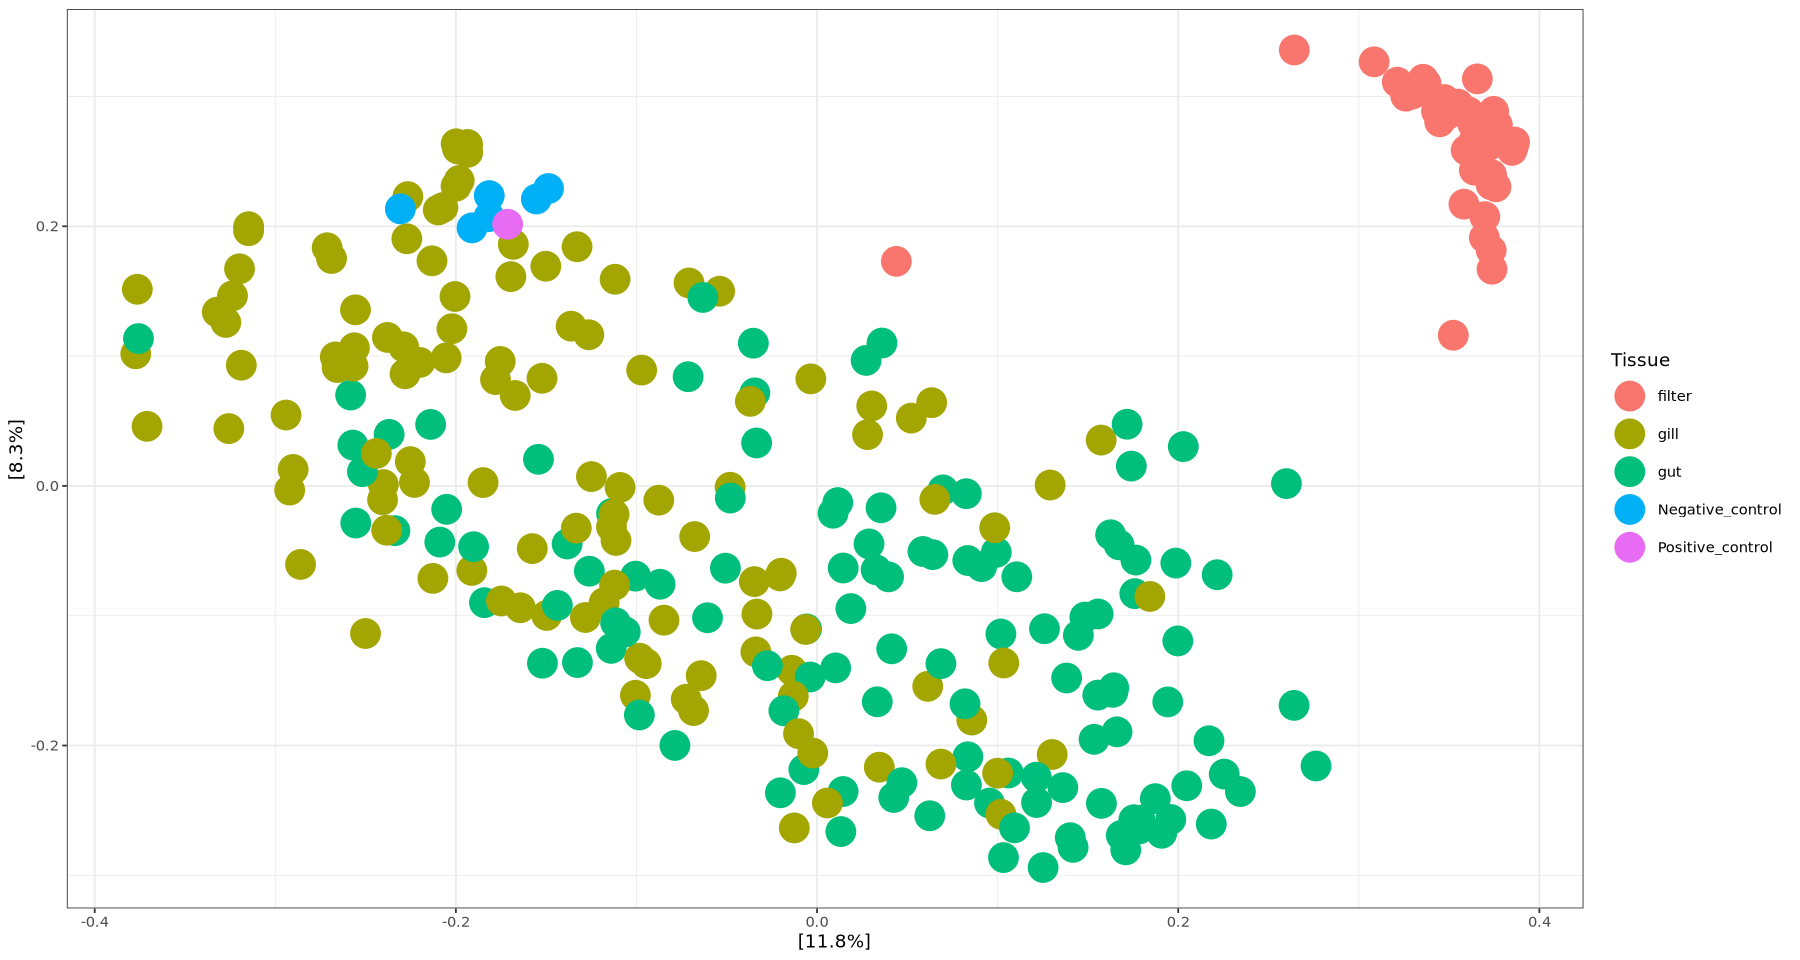

In [5]:
# PCoA ordination of all samples
all.ord <- ordinate(ps, "PCoA", "bray")

# Plot PCoA of all samples
plot_ordination(ps, all.ord, color = "Tissue") +
    geom_point(size=8) +
    theme_bw()

- Filter samples separate pretty neatly from tissue and control samples
- Gill and gut tissues have a large overlap but some distinction along the x and y axes
- Negative controls cluster within the gill tissue, likely contamination with samples

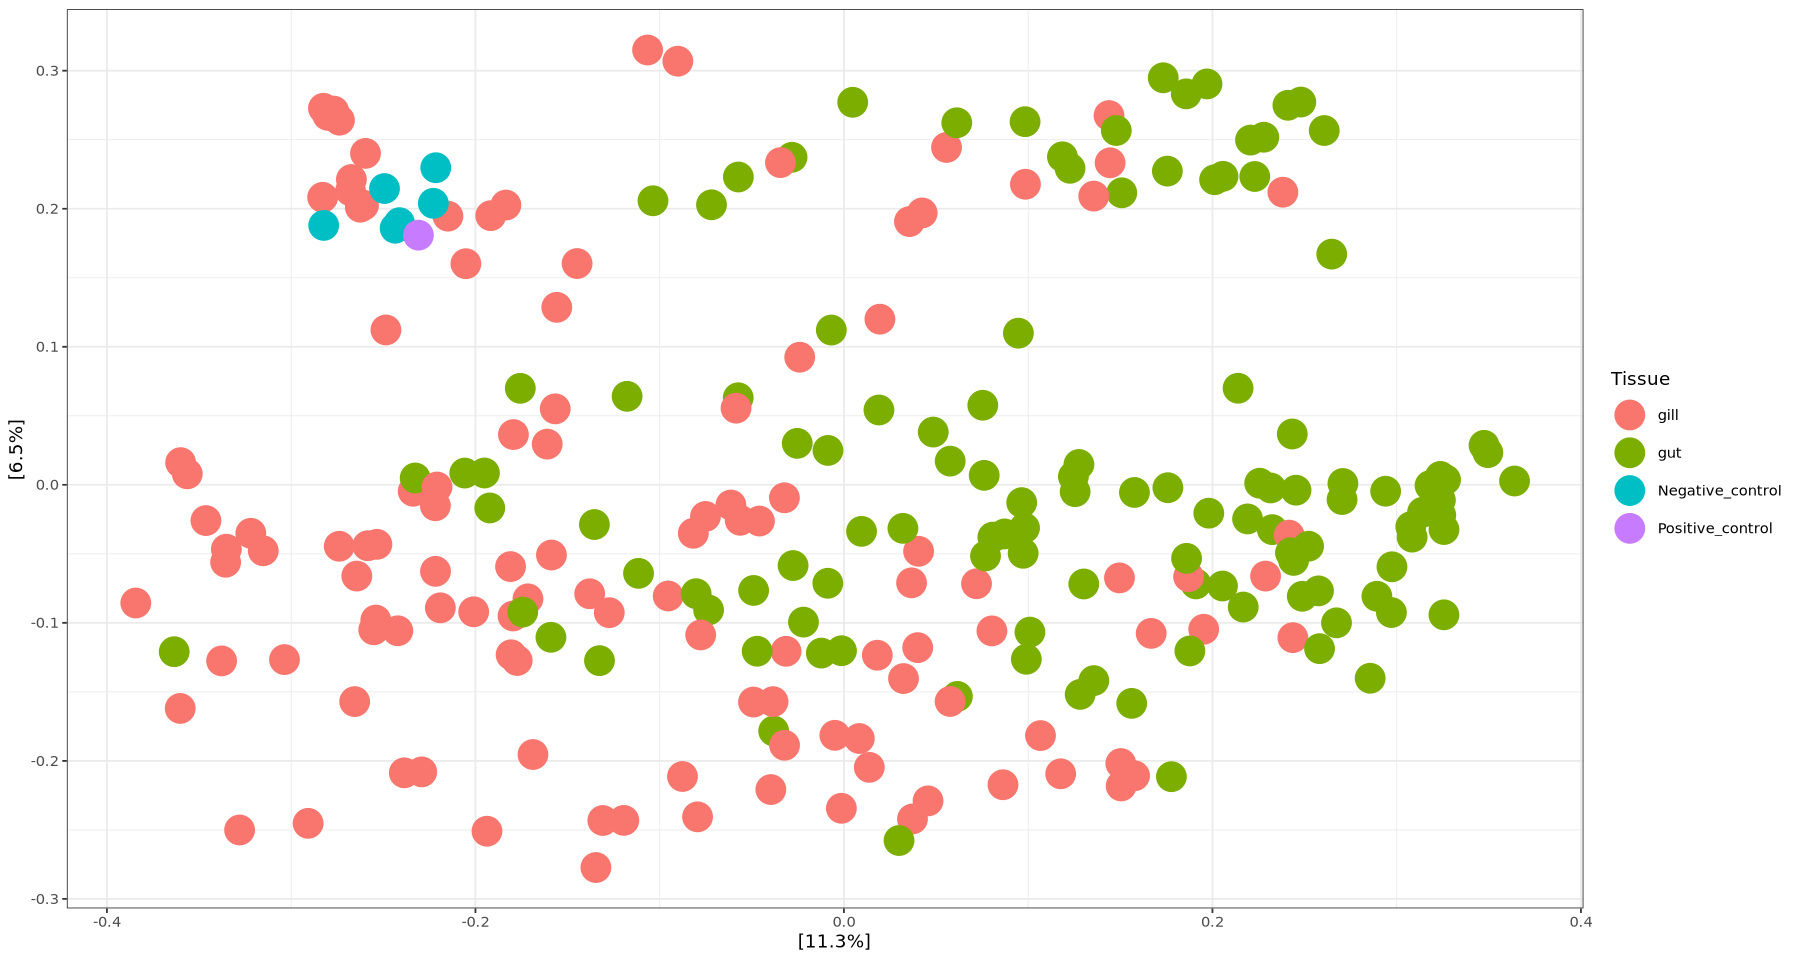

In [6]:
# Remove filter samples from PCoA, ordinate, and plot
ps_tissue <- subset_samples(ps, is.na(Tissue) | Tissue != "filter")
tissue.ord <- ordinate(ps_tissue, "PCoA", "bray")
plot_ordination(ps_tissue, tissue.ord, color = "Tissue") +
    geom_point(size=8) +
    theme_bw()

- Gill and gut tissues seem to overlap more, especially along the y-axis
- Negative controls still cluster within the gill tissue

In [ ]:
# Add label to negative and positive controls in the tissue column
sample_data(ps_bacteria)$Tissue[grepl("negative", sample_names(ps_bacteria))] <- "Negative_control"
sample_data(ps_bacteria)$Tissue[grepl("Positive", sample_names(ps_bacteria))] <- "Positive_control"

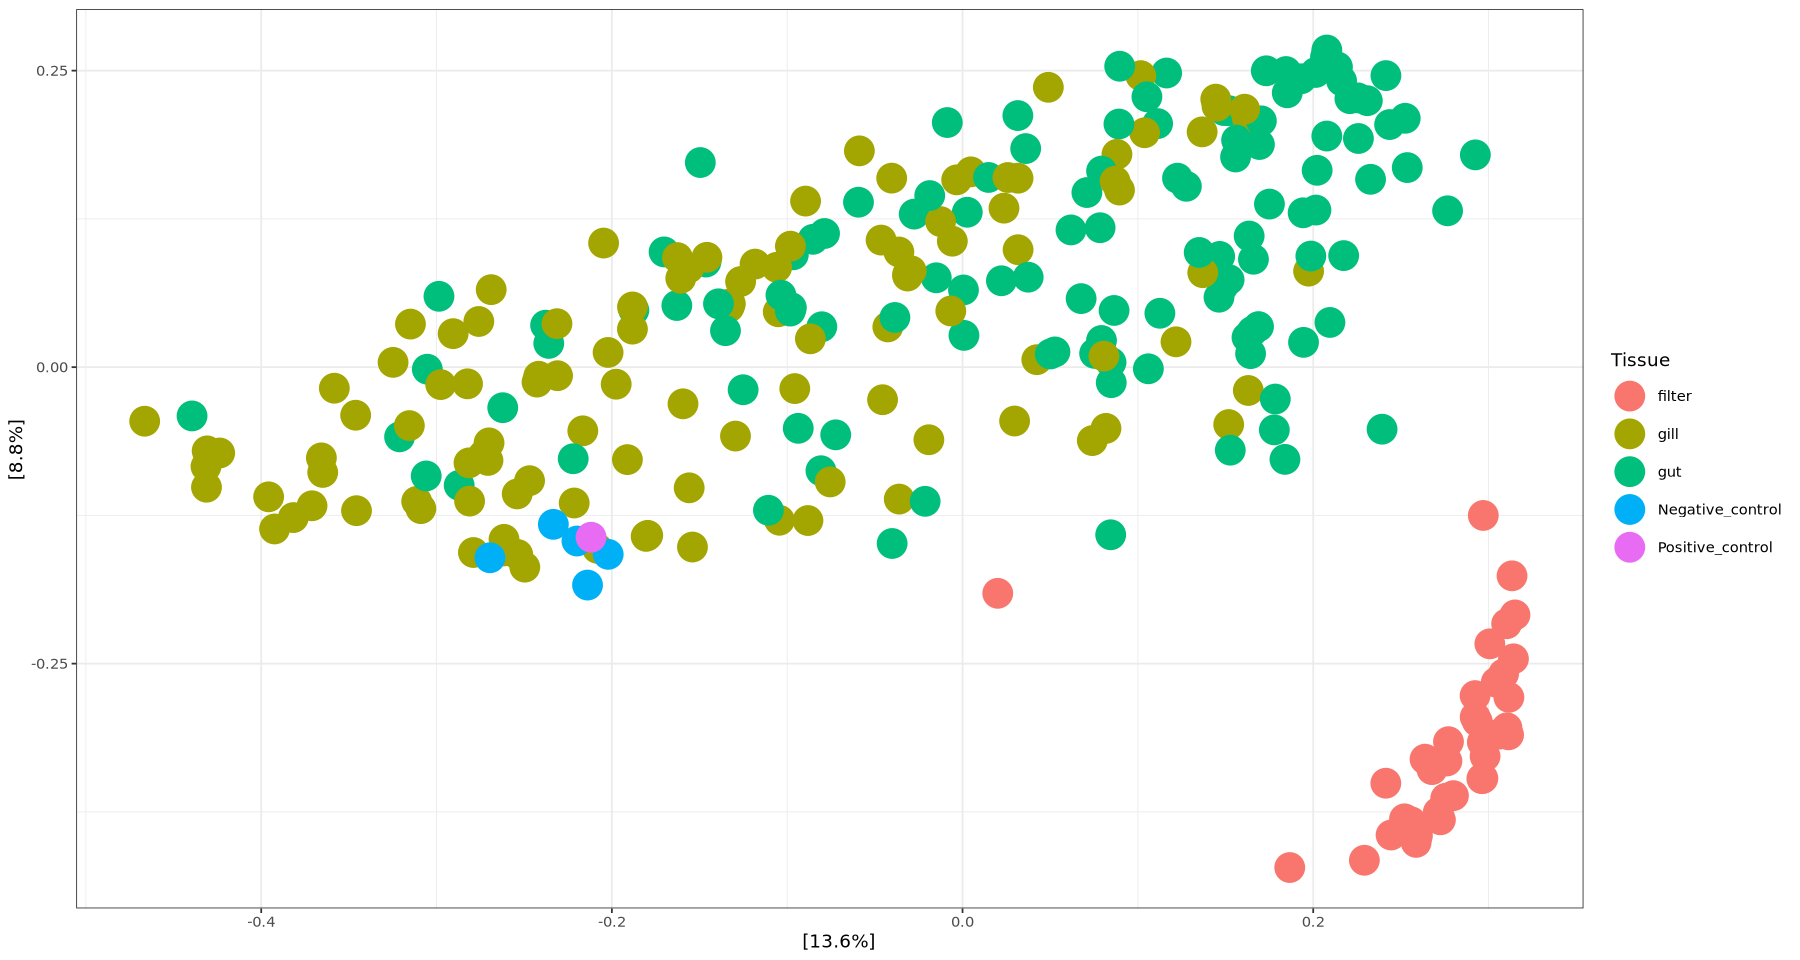

In [10]:
# Ordinate and plot PCoA
bacteria_all.ord <- ordinate(ps_bacteria, "PCoA", "bray")
plot_ordination(ps_bacteria, bacteria_all.ord, color = "Tissue") +
    geom_point(size=8) +
    theme_bw()

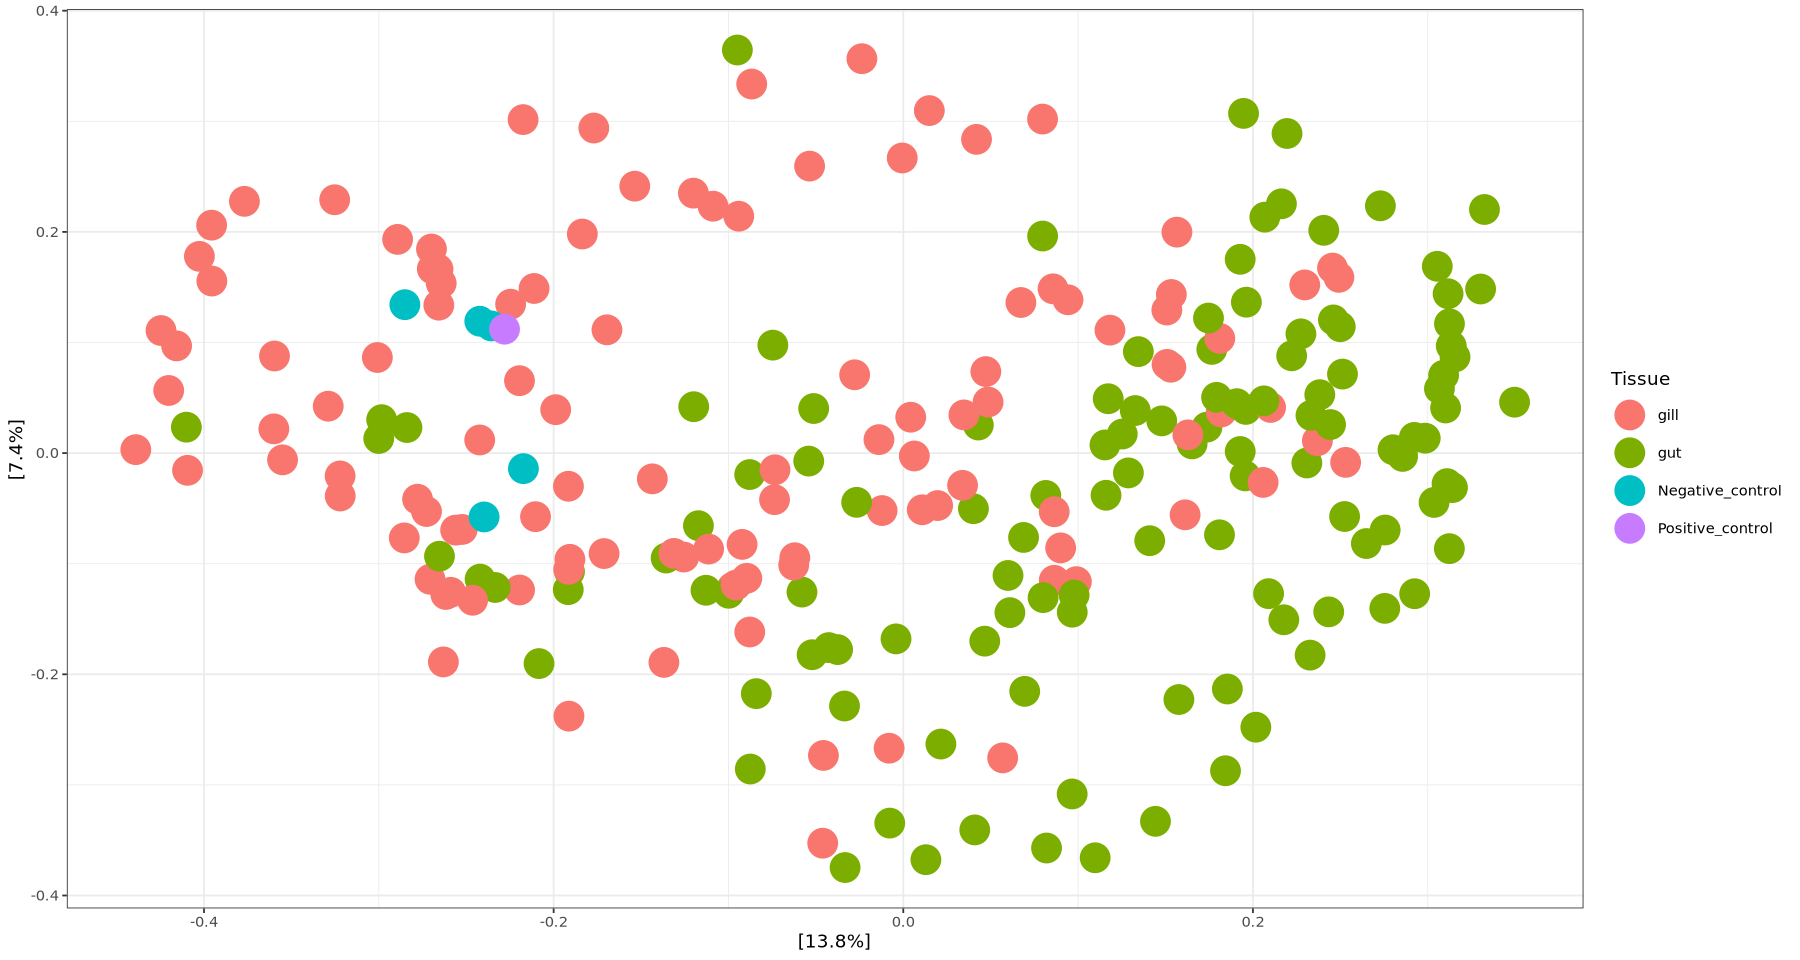

In [12]:
# Remove filter samples
ps_bacteria_tissue <- subset_samples(ps_bacteria, is.na(Tissue) | Tissue != "filter")

# Ordinate and plot PCoA
bacteria_tissue.ord <- ordinate(ps_bacteria_tissue, "PCoA", "bray")
plot_ordination(ps_bacteria_tissue, bacteria_tissue.ord, color = "Tissue") +
    geom_point(size=8) +
    theme_bw()

## Normalized, bacteria-only phyloseq object

To account for bray-curtis sensitivity to sequencing depth, best practice is to ordinate and plot using the normalized abundances. See `2.1_phyloseq-dada2.ipynb` for a different method of cleaning the phyloseq object to attain relative abundances. 

In [14]:
# Read in raw phyloseq object
ps_norm <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps-objects/ps-decipher-norm.rds")

In [17]:
# Add label to negative and positive controls in the tissue column
sample_data(ps_norm)$Tissue[grepl("negative", sample_names(ps_norm))] <- "Negative_control"
sample_data(ps_norm)$Tissue[grepl("Positive", sample_names(ps_norm))] <- "Positive_control"

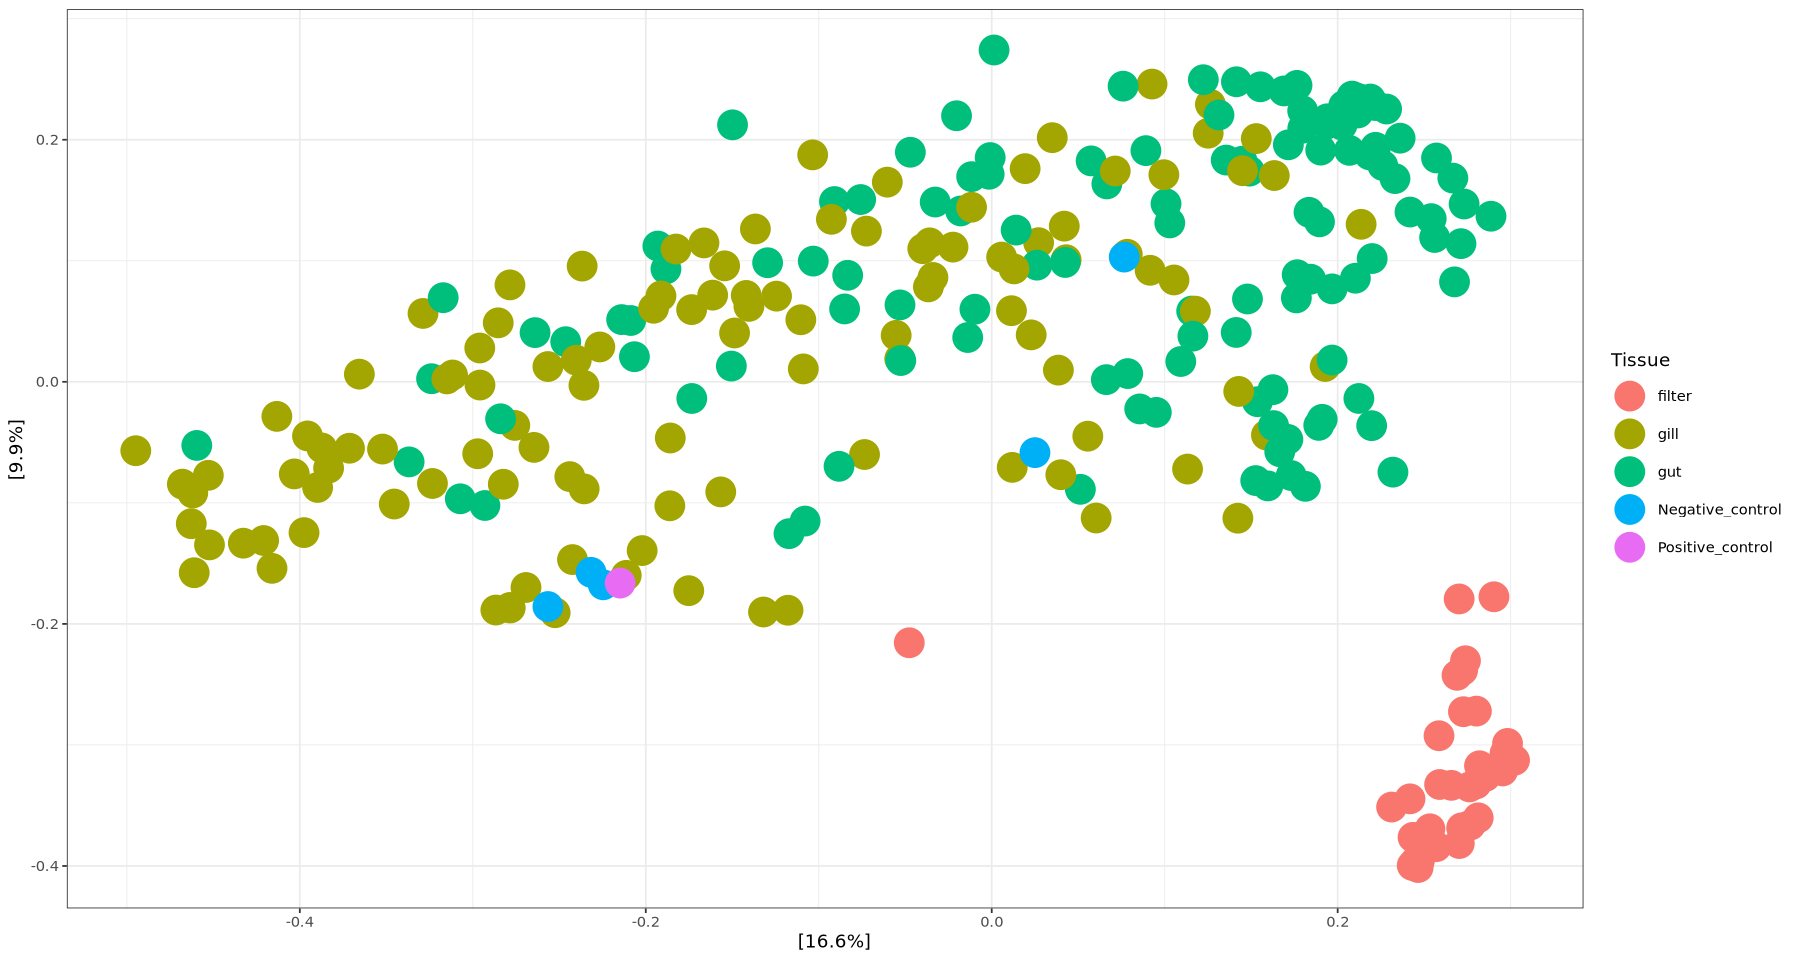

In [18]:
# Ordinate and plot PCoA
norm_all.ord <- ordinate(ps_norm, "PCoA", "bray")
plot_ordination(ps_norm, norm_all.ord, color = "Tissue") +
    geom_point(size=8) +
    theme_bw()

- Filter samples are distinct from tissue and control samples
- Gill and gut tissues largely overlap, though gut tissue seems to cluster more tightly together
- Negative controls don't all cluster 

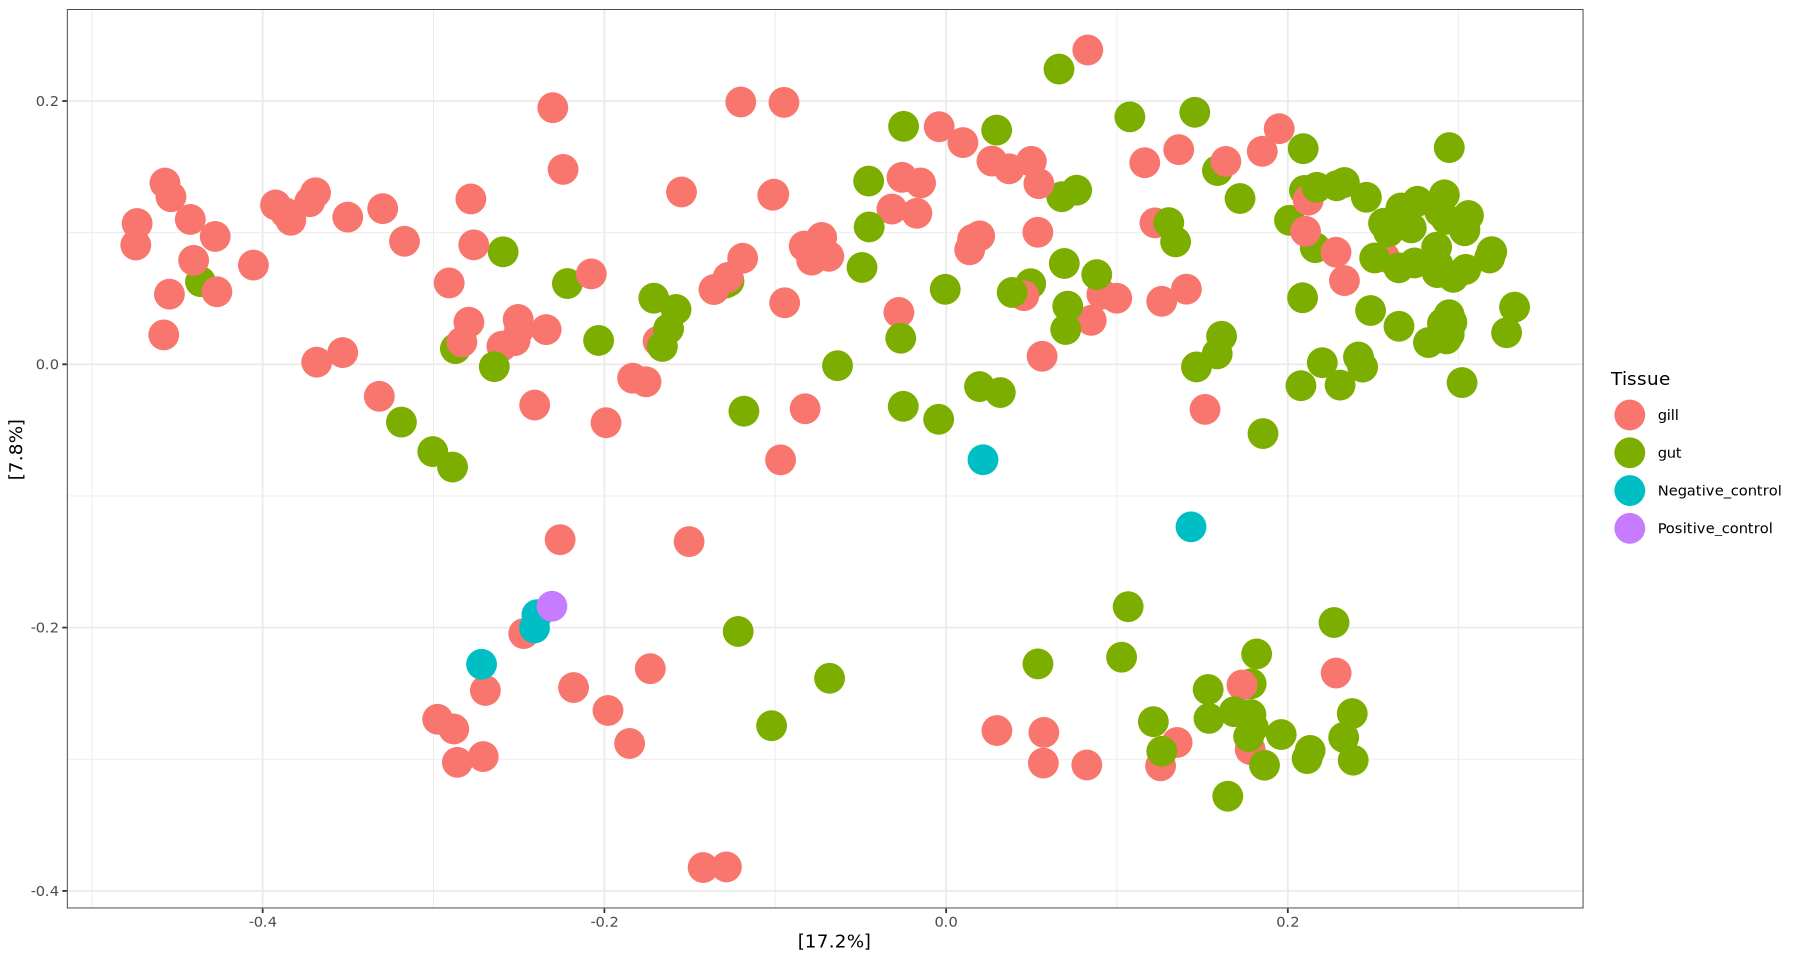

In [19]:
# Remove filter samples
ps_norm_tissue <- subset_samples(ps_norm, is.na(Tissue) | Tissue != "filter")

# Ordinate and plot PCoA
norm_tissue.ord <- ordinate(ps_norm_tissue, "PCoA", "bray")
plot_ordination(ps_norm_tissue, norm_tissue.ord, color = "Tissue") +
    geom_point(size=8) +
    theme_bw()

- Tissues, regardless of gill or gut, seem to have two distinct groupings along the y-axis
- Negative controls remain spread across the x-axis, but do appear to sit between the two groupings along the y-axis